In [1]:
from dotenv import load_dotenv
load_dotenv()

True

In [11]:
from langgraph.graph import StateGraph,START,END
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph.message import add_messages
from pydantic import BaseModel
from typing import Annotated
from langchain_groq import ChatGroq

In [10]:
class ChatState(BaseModel):
    messages:Annotated[list,add_messages]

In [13]:
llm=ChatGroq(model="openai/gpt-oss-20b")

In [14]:
def chat_bot_node(state:ChatState)->ChatState:
    res=llm.invoke(state.messages)
    state.messages=[res]
    return state

In [15]:
memory=InMemorySaver()

In [16]:
graph=StateGraph(ChatState)
graph.add_node("chat_bot_node",chat_bot_node)
graph.add_edge(START,"chat_bot_node")
graph.add_edge("chat_bot_node",END)

graph=graph.compile(checkpointer=InMemorySaver())

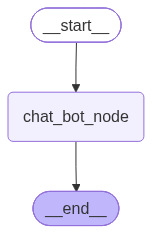

In [17]:
from IPython.display import Image
Image(graph.get_graph().draw_mermaid_png())

In [19]:
config={"configurable":{"thread_id":"1"}}

res=graph.invoke({"messages":{"role":"user","content":"Hello How are you "}},
                 config=config)


res['messages'][-1].content

'Hello! I’m just a bundle of code, so I don’t have feelings, but I’m here and ready to help you. How can I assist you today?'